# 03 · Modelado

**Objetivo:** construir y comparar modelos de prevención de fraude según su ganancia,
usando solo entrenamiento y validación. La evaluación final en test se hace en el notebook 04.

## 1. Librerías y datos

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import lightgbm as lgb
import xgboost as xgb
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import KBinsDiscretizer, OneHotEncoder
from sklearn.metrics import roc_auc_score, log_loss
from sklearn.base import clone

from src.data import cargar_config, cargar_datos, separar_temporal
from src.features import PreparadorVariables
from src.business import buscar_umbral, metricas_negocio, umbral_teorico

import warnings

# KBinsDiscretizer fusiona tramos en variables con muchos valores repetidos (por ejemplo, `d`,
# con el 25% de sus valores en 50). Es esperado y no afecta el resultado.
warnings.filterwarnings("ignore", message="Bins whose width are too small")

In [2]:
config = cargar_config()
df = cargar_datos(config)

# Test no se usa en este notebook: la evaluación final se hace en el notebook 04
entrenamiento, validacion, _ = separar_temporal(df, config)
del df

print(f"Entrenamiento: {len(entrenamiento):,} | Validación: {len(validacion):,}")

Entrenamiento: 90,063 | Validación: 24,443


## 2. Construcción de variables

In [3]:
preparador = PreparadorVariables(usar_score=False).fit(entrenamiento)

X_entrenamiento = preparador.transform(entrenamiento)
X_validacion = preparador.transform(validacion)
y_entrenamiento = entrenamiento["fraude"]
y_validacion = validacion["fraude"]

assert list(X_entrenamiento.columns) == list(X_validacion.columns), "Las columnas no coinciden"

X_entrenamiento.dtypes

b                float64
c                float64
d                float64
e                float64
f                float64
h                  int64
l                float64
m                float64
monto            float64
hora               int32
n                  int64
p                  int64
a               category
g               category
o               category
j_frecuencia       int64
dtype: object

In [4]:
print("Categorías aprendidas en entrenamiento:")
for columna, categorias in preparador.categorias_.items():
    print(f"  {columna}: {categorias}")

pd.DataFrame({
    "nulos_entrenamiento_pct": (X_entrenamiento.isna().mean() * 100).round(2),
    "nulos_validacion_pct": (X_validacion.isna().mean() * 100).round(2),
})

Categorías aprendidas en entrenamiento:
  a: ['1', '2', '3', '4']
  g: ['AR', 'BR', 'MX', 'SE', 'US', 'UY', 'nulo', 'otros']
  o: ['N', 'Y', 'nulo']


,nulos_entrenamiento_pct,nulos_validacion_pct
b,13.83,0.82
c,13.83,0.82
d,0.30,0.25
e,0.00,0.00
f,0.01,0.01
h,0.00,0.00
l,0.01,0.01
m,0.30,0.25
monto,0.00,0.00
hora,0.00,0.00


## 3. Referencias: aprobar todo y score actual

In [5]:
margen = config["margen_ganancia"]
monto_validacion = validacion["monto"]

# Aprobar todo: ninguna transacción se rechaza
aprobar_todo = metricas_negocio(y_validacion, monto_validacion, rechazar=np.zeros(len(validacion), dtype=bool), margen=margen)

# Score actual: se prueba cada corte posible; con 101 no se rechaza nada
curva_score = buscar_umbral(y_validacion, monto_validacion, validacion["score"], umbrales=range(0, 102), margen=margen)
mejor_corte_score = curva_score.loc[curva_score["ganancia"].idxmax(), "umbral"]
score_actual = metricas_negocio(y_validacion, monto_validacion, rechazar=validacion["score"] >= mejor_corte_score, margen=margen)

print(f"Mejor corte del score en validación: {mejor_corte_score}")
pd.DataFrame({"Aprobar todo": aprobar_todo, f"Score >= {mejor_corte_score}": score_actual}).round(2)

Mejor corte del score en validación: 86


,Aprobar todo,Score >= 86
ganancia,128268.77,155783.85
pct_monto_fraude_evitado,0.00,49.99
precision_monto_rechazadas,NaN,38.05
tasa_aprobacion,100.00,91.54


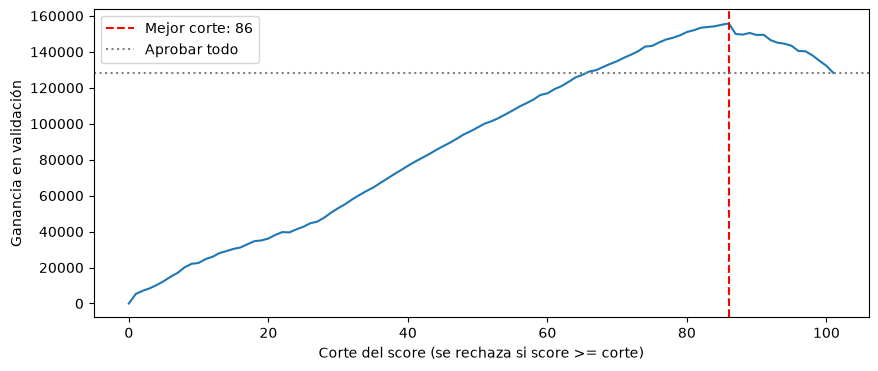

In [6]:
plt.figure(figsize=(10, 4))
plt.plot(curva_score["umbral"], curva_score["ganancia"])
plt.axvline(mejor_corte_score, color="red", linestyle="--", label=f"Mejor corte: {mejor_corte_score}")
plt.axhline(aprobar_todo["ganancia"], color="gray", linestyle=":", label="Aprobar todo")
plt.xlabel("Corte del score (se rechaza si score >= corte)")
plt.ylabel("Ganancia en validación")
plt.legend()
plt.show()

**Observaciones:**
- Aprobar todo deja una ganancia de 128.269 en validación.
- El score actual, con su mejor corte (rechazar si score >= 86), sube la ganancia a 155.784
  (+21%): rechaza el 8,5% de las compras y evita el 50% del dinero de fraude.
- El mejor corte en dinero (86) es más bajo que el que sugería la tasa de fraude por cantidad
  de transacciones en el EDA (cerca de 98), porque los fraudes con score alto son de montos altos.
- La ganancia es parecida para cortes entre 82 y 90, así que la elección del corte es estable.
- El corte se eligió en validación, igual que se hará con los umbrales de los modelos.
  Por eso todos los resultados de validación son algo optimistas, pero por igual.

**Referencia a superar:** 155.784 de ganancia en validación.

## 4. Regresión logística

Las variables numéricas se convierten en 10 tramos de igual tamaño (deciles). Esto resuelve
lo encontrado en el EDA: las relaciones no lineales (la U de `c`, el salto de `b` en sus valores altos),
los valores extremos y la falta de escala común. Los nulos se imputan con la mediana de entrenamiento.
Las categóricas y la hora se codifican con una columna por valor.

In [7]:
numericas = ["b", "c", "d", "e", "f", "h", "l", "m", "monto", "j_frecuencia"]
categoricas = ["a", "g", "o", "hora"]
binarias = ["n", "p"]

preprocesamiento = ColumnTransformer([
    ("numericas", make_pipeline(
        SimpleImputer(strategy="median"),
        KBinsDiscretizer(n_bins=10, strategy="quantile", encode="onehot", quantile_method="averaged_inverted_cdf"),
    ), numericas),
    ("categoricas", OneHotEncoder(handle_unknown="ignore"), categoricas),
    ("binarias", "passthrough", binarias),
])

modelo_logistico = Pipeline([
    ("preprocesamiento", preprocesamiento),
    ("modelo", LogisticRegression(max_iter=1000)),
])

modelo_logistico.fit(X_entrenamiento, y_entrenamiento)
proba_logistica = modelo_logistico.predict_proba(X_validacion)[:, 1]

In [8]:
print(f"AUC de la regresión logística en validación: {roc_auc_score(y_validacion, proba_logistica):.3f}")

# Ganancia para cada umbral de probabilidad, de 0 a 1 en pasos de 0,01
curva_logistica = buscar_umbral(y_validacion, monto_validacion, proba_logistica, umbrales=np.round(np.arange(0, 1.01, 0.01), 2), margen=margen)
mejor_umbral_logistica = curva_logistica.loc[curva_logistica["ganancia"].idxmax(), "umbral"]

logistica_empirico = metricas_negocio(y_validacion, monto_validacion, rechazar=proba_logistica >= mejor_umbral_logistica, margen=margen)
logistica_teorico = metricas_negocio(y_validacion, monto_validacion, rechazar=proba_logistica >= umbral_teorico(margen), margen=margen)

pd.DataFrame({
    "Aprobar todo": aprobar_todo,
    f"Score >= {mejor_corte_score}": score_actual,
    f"Logística, umbral teórico ({umbral_teorico(margen):.2f})": logistica_teorico,
    f"Logística, umbral empírico ({mejor_umbral_logistica})": logistica_empirico,
}).round(2)

AUC de la regresión logística en validación: 0.840


,Aprobar todo,Score >= 86,"Logística, umbral teórico (0.20)","Logística, umbral empírico (0.2)"
ganancia,128268.77,155783.85,161227.87,161227.87
pct_monto_fraude_evitado,0.00,49.99,47.35,47.35
precision_monto_rechazadas,NaN,38.05,49.99,49.99
tasa_aprobacion,100.00,91.54,94.63,94.63


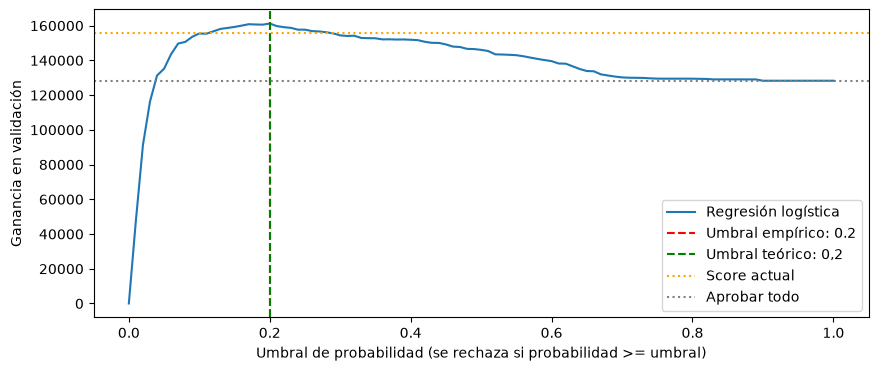

In [9]:
plt.figure(figsize=(10, 4))
plt.plot(curva_logistica["umbral"], curva_logistica["ganancia"], label="Regresión logística")
plt.axvline(mejor_umbral_logistica, color="red", linestyle="--", label=f"Umbral empírico: {mejor_umbral_logistica}")
plt.axvline(umbral_teorico(margen), color="green", linestyle="--", label="Umbral teórico: 0,2")
plt.axhline(score_actual["ganancia"], color="orange", linestyle=":", label="Score actual")
plt.axhline(aprobar_todo["ganancia"], color="gray", linestyle=":", label="Aprobar todo")
plt.xlabel("Umbral de probabilidad (se rechaza si probabilidad >= umbral)")
plt.ylabel("Ganancia en validación")
plt.legend()
plt.show()

**Observaciones:**
- La regresión logística, sin usar el score, alcanza una ganancia de 161.228 en validación:
  5.444 más que el score actual (+3,5%) y 32.959 más que aprobar todo.
- Evita casi el mismo dinero de fraude que el score (47,4% frente a 50,0%), pero aprueba más compras
  (94,6% frente a 91,5%) y la mitad del dinero que rechaza es fraude (frente a 38,1% del score).
  Es decir, molesta a menos clientes legítimos.
- El umbral que maximiza la ganancia es 0,2, igual al teórico: las probabilidades del modelo
  están bien calibradas.
- La ganancia es parecida para umbrales entre 0,15 y 0,30, así que el umbral es estable.
- La ventaja sobre el score es pequeña; se confirmará con bootstrap.

**Referencia a superar:** 161.228 de ganancia en validación.

## 5. Modelos de boosting

### 5.1 Evaluación común para todos los modelos
Todos los modelos se evalúan igual: se busca el umbral de probabilidad con mayor ganancia
en validación y se calculan las métricas de negocio con ese umbral.

In [10]:
def evaluar_modelo(proba):
    """Ganancia y métricas de negocio con el mejor umbral en validación, más el AUC."""
    curva = buscar_umbral(y_validacion, monto_validacion, proba, umbrales=np.round(np.arange(0, 1.01, 0.01), 2), margen=margen)
    mejor_umbral = curva.loc[curva["ganancia"].idxmax(), "umbral"]
    metricas = metricas_negocio(y_validacion, monto_validacion, rechazar=proba >= mejor_umbral, margen=margen)
    metricas["umbral"] = mejor_umbral
    metricas["auc"] = roc_auc_score(y_validacion, proba)
    return metricas, curva


resultados = {
    "Aprobar todo": aprobar_todo,
    f"Score >= {mejor_corte_score}": score_actual,
    "Regresión logística": evaluar_modelo(proba_logistica)[0],
}

### 5.2 Ajuste de hiperparámetros

Se prueban 30 combinaciones al azar para cada algoritmo de boosting, con rangos equivalentes,
y varios valores de regularización para la regresión logística. Cada combinación se mide con
log-loss en validación, porque es una métrica estable que además favorece probabilidades confiables.
La ganancia se reserva para elegir el umbral y el modelo final.

Los hiperparámetros se ajustan en validación. Esto hace optimistas los resultados de validación,
por igual para todos los modelos; la evaluación honesta se hace en test.

In [11]:
espacio_lgbm = {
    "num_leaves": [15, 31, 63, 127],
    "min_child_samples": [20, 50, 100, 200],
    "reg_lambda": [0, 1, 5, 10],
    "colsample_bytree": [0.6, 0.8, 1.0],
}

generador = np.random.default_rng(config["seed"])
pruebas_lgbm = []

for _ in range(30):
    parametros = {nombre: generador.choice(valores).item() for nombre, valores in espacio_lgbm.items()}

    modelo = lgb.LGBMClassifier(
        n_estimators=2000,
        learning_rate=0.03,
        subsample=0.8,
        subsample_freq=1,
        random_state=config["seed"],
        verbose=-1,
        **parametros,
    )
    modelo.fit(
        X_entrenamiento,
        y_entrenamiento,
        eval_X=X_validacion,
        eval_y=y_validacion,
        eval_metric="binary_logloss",
        callbacks=[lgb.early_stopping(100, verbose=False)],
    )

    proba = modelo.predict_proba(X_validacion)[:, 1]
    pruebas_lgbm.append({**parametros, "arboles": modelo.best_iteration_, "log_loss": log_loss(y_validacion, proba)})

pruebas_lgbm = pd.DataFrame(pruebas_lgbm).sort_values("log_loss")
pruebas_lgbm.head(10)

,num_leaves,min_child_samples,reg_lambda,colsample_bytree,arboles,log_loss
21,31,50,10,0.6,394,0.155065
0,15,50,5,1.0,543,0.155081
12,15,50,5,1.0,543,0.155081
9,31,20,10,0.8,381,0.155144
3,31,50,5,0.6,356,0.155174
13,15,100,5,0.6,538,0.155210
6,15,50,1,0.6,665,0.155229
24,31,200,10,1.0,387,0.155266
5,31,100,1,0.8,343,0.155280
20,31,50,1,0.8,344,0.155355


In [12]:
pruebas_lgbm.tail(5)

,num_leaves,min_child_samples,reg_lambda,colsample_bytree,arboles,log_loss
2,63,100,0,0.6,254,0.156157
23,127,50,5,0.6,231,0.156179
8,127,100,5,0.8,192,0.156680
29,127,200,5,1.0,183,0.156767
10,127,50,0,1.0,136,0.157309


**Observaciones (LightGBM):**
- Las diferencias de log-loss entre combinaciones son pequeñas (de 0,1551 a 0,1573):
  el modelo es poco sensible a sus hiperparámetros.
- Las mejores combinaciones usan árboles simples (15 o 31 hojas) y regularización;
  las peores usan árboles complejos (63 o 127 hojas), que se sobreajustan antes.
- Mejor combinación: 31 hojas, mínimo 50 transacciones por hoja, `reg_lambda` 10
  y 60% de columnas por árbol.

In [13]:
espacio_xgb = {
    "max_depth": [3, 4, 5, 6],
    "min_child_weight": [1, 5, 10, 20],
    "reg_lambda": [0, 1, 5, 10],
    "colsample_bytree": [0.6, 0.8, 1.0],
}

generador = np.random.default_rng(config["seed"])
pruebas_xgb = []

for _ in range(30):
    parametros = {nombre: generador.choice(valores).item() for nombre, valores in espacio_xgb.items()}

    modelo = xgb.XGBClassifier(
        n_estimators=2000,
        learning_rate=0.03,
        subsample=0.8,
        tree_method="hist",
        enable_categorical=True,
        eval_metric="logloss",
        early_stopping_rounds=100,
        random_state=config["seed"],
        **parametros,
    )
    modelo.fit(X_entrenamiento, y_entrenamiento, eval_set=[(X_validacion, y_validacion)], verbose=False)

    proba = modelo.predict_proba(X_validacion)[:, 1]
    pruebas_xgb.append({**parametros, "arboles": modelo.best_iteration + 1, "log_loss": log_loss(y_validacion, proba)})

pruebas_xgb = pd.DataFrame(pruebas_xgb).sort_values("log_loss")
pruebas_xgb.head(10)

,max_depth,min_child_weight,reg_lambda,colsample_bytree,arboles,log_loss
24,4,20,10,1.0,827,0.154964
22,5,20,5,1.0,547,0.154999
4,5,10,10,1.0,692,0.155040
27,5,10,10,1.0,692,0.155040
19,5,20,10,1.0,551,0.155074
1,5,20,10,1.0,551,0.155074
21,4,5,10,0.6,886,0.155143
20,4,5,1,0.8,724,0.155151
9,4,1,10,0.8,713,0.155180
16,5,1,10,0.6,633,0.155181


**Observaciones (XGBoost):**
- Igual que en LightGBM, las diferencias de log-loss entre combinaciones son pequeñas
  (las 10 mejores, entre 0,1550 y 0,1552).
- Las mejores combinaciones usan árboles de profundidad moderada (4 o 5) y regularización fuerte.
- Mejor combinación: profundidad 4, `min_child_weight` 20, `reg_lambda` 10 y todas las columnas.
- Con el mismo esfuerzo de ajuste, la mejor log-loss de XGBoost (0,15496) y la de LightGBM (0,15507)
  son prácticamente iguales.

In [14]:
pruebas_logistica = []

for C in [0.01, 0.03, 0.1, 0.3, 1, 3, 10]:
    modelo = clone(modelo_logistico).set_params(modelo__C=C)
    modelo.fit(X_entrenamiento, y_entrenamiento)
    proba = modelo.predict_proba(X_validacion)[:, 1]
    pruebas_logistica.append({"C": C, "log_loss": log_loss(y_validacion, proba)})

pruebas_logistica = pd.DataFrame(pruebas_logistica).sort_values("log_loss")
pruebas_logistica

,C,log_loss
2,0.10,0.160959
1,0.03,0.160996
3,0.30,0.161043
4,1.00,0.161105
5,3.00,0.161127
6,10.00,0.161136
0,0.01,0.161668


**Observaciones (regresión logística):**
- La mejor regularización es `C` = 0,1, con una log-loss apenas menor que el valor por defecto (`C` = 1).
- La log-loss de la regresión (0,161) es mayor que la de los dos boosting (0,155):
  sus probabilidades son menos precisas.

### 5.3 Modelos ajustados

In [19]:
def mejores_parametros(pruebas, espacio):
    """Toma la mejor combinación de una búsqueda, respetando el tipo de cada hiperparámetro."""
    mejor = pruebas.iloc[0]
    return {nombre: type(valores[0])(mejor[nombre]) for nombre, valores in espacio.items()}

parametros_lgbm = mejores_parametros(pruebas_lgbm, espacio_lgbm)
parametros_xgb = mejores_parametros(pruebas_xgb, espacio_xgb)
C_logistica = pruebas_logistica.iloc[0]["C"]

print(f"LightGBM: {parametros_lgbm}")
print(f"XGBoost: {parametros_xgb}")
print(f"Regresión logística: C = {C_logistica}")

LightGBM: {'num_leaves': 31, 'min_child_samples': 50, 'reg_lambda': 10, 'colsample_bytree': 0.6}
XGBoost: {'max_depth': 4, 'min_child_weight': 20, 'reg_lambda': 10, 'colsample_bytree': 1.0}
Regresión logística: C = 0.1


In [18]:
modelo_logistico_final = clone(modelo_logistico).set_params(modelo__C=C_logistica)
modelo_logistico_final.fit(X_entrenamiento, y_entrenamiento)
proba_logistica = modelo_logistico_final.predict_proba(X_validacion)[:, 1]

modelo_lgbm = lgb.LGBMClassifier(
    n_estimators=2000, learning_rate=0.03, subsample=0.8, subsample_freq=1,
    random_state=config["seed"], verbose=-1, **parametros_lgbm,
)
modelo_lgbm.fit(
    X_entrenamiento, y_entrenamiento, eval_X=X_validacion, eval_y=y_validacion,
    eval_metric="binary_logloss", callbacks=[lgb.early_stopping(100, verbose=False)],
)
proba_lgbm = modelo_lgbm.predict_proba(X_validacion)[:, 1]

modelo_xgb = xgb.XGBClassifier(
    n_estimators=2000, learning_rate=0.03, subsample=0.8, tree_method="hist",
    enable_categorical=True, eval_metric="logloss", early_stopping_rounds=100,
    random_state=config["seed"], **parametros_xgb,
)
modelo_xgb.fit(X_entrenamiento, y_entrenamiento, eval_set=[(X_validacion, y_validacion)], verbose=False)
proba_xgb = modelo_xgb.predict_proba(X_validacion)[:, 1]

curvas = {}
resultados["Regresión logística"], curvas["Regresión logística"] = evaluar_modelo(proba_logistica)
resultados["LightGBM"], curvas["LightGBM"] = evaluar_modelo(proba_lgbm)
resultados["XGBoost"], curvas["XGBoost"] = evaluar_modelo(proba_xgb)

for nombre, proba in [("Regresión logística", proba_logistica), ("LightGBM", proba_lgbm), ("XGBoost", proba_xgb)]:
    resultados[nombre]["ganancia_umbral_0.2"] = metricas_negocio(
        y_validacion, monto_validacion, rechazar=proba >= umbral_teorico(margen), margen=margen
    )["ganancia"]

pd.DataFrame(resultados).round(3)

,Aprobar todo,Score >= 86,Regresión logística,LightGBM,XGBoost
ganancia,128268.772,155783.855,161342.848,163532.665,162344.408
pct_monto_fraude_evitado,0.000,49.994,47.144,48.917,50.321
precision_monto_rechazadas,NaN,38.047,50.588,52.814,48.035
tasa_aprobacion,100.000,91.540,94.751,95.635,95.042
umbral,NaN,NaN,0.200,0.230,0.210
auc,NaN,NaN,0.841,0.852,0.852
ganancia_umbral_0.2,NaN,NaN,161342.848,162195.755,162086.550


**Observaciones:**
- Con los hiperparámetros ajustados, el umbral que maximiza la ganancia queda cerca del teórico
  en los tres modelos: 0,20 en la regresión logística, 0,21 en XGBoost y 0,23 en LightGBM.
  Esto indica que sus probabilidades están bien calibradas.
- Con el umbral teórico (0,2), los tres modelos quedan a menos de 1.000 de diferencia entre sí.

**Decisión:** se usa el umbral teórico de 0,2 para todos los modelos, porque están bien calibrados
y así el umbral no depende de los datos de validación.